# Unit 2 — Advanced Visualization & Storytelling (UE24CS342AA9)
## Activity Notebook: Building the Global Development Monitor

### Scenario

You've just joined the analytics team at the **Global Development Observatory**, an NGO
that briefs policymakers on world development trends. Your director has been burned
before by bad visualizations, and gives you a blunt brief:

1. *"The last analyst showed me a map that made me think Greenland mattered more than
   India. Don't let that happen again."*
2. *"We're about to publish a model predicting life expectancy. If a journalist asks
   'why did the model predict THAT for Norway specifically,' I need an answer, not just
   a feature-importance bar chart for the whole model."*
3. *"Every number in our reports is an estimate. I want our numbers to LOOK like
   estimates, not like certainties."*
4. *"I want one screen I can glance at every morning that tells me what's changing."*

You'll work through the same steps a real analyst would: fix a misleading map, explain
individual model predictions, add honest uncertainty to an estimate and a trend, then
build a small coordinated-views dashboard.

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection**
are for you to answer in your own words.

## Part 0 — Setup (given)

Run this cell as-is. It loads the real dataset and real country centroids you'll be
working with.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

import plotly.express as px
from sklearn.ensemble import RandomForestRegressor
import shap

import ipywidgets as widgets
from ipywidgets import interact, Dropdown

np.random.seed(0)

gapminder = px.data.gapminder()
centroids = pd.read_csv("country_centroids_computed.csv")
gap_latest = gapminder[gapminder.year == 2007].merge(centroids, on="iso_alpha", how="left")
gap_latest = gap_latest.assign(total_gdp=gap_latest["pop"] * gap_latest.gdpPercap)

print(f"Loaded {gapminder.country.nunique()} countries, years {sorted(gapminder.year.unique())}.")
gap_latest[["country", "continent", "year", "lifeExp", "pop", "gdpPercap"]].head()

Loaded 142 countries, years [np.int64(1952), np.int64(1957), np.int64(1962), np.int64(1967), np.int64(1972), np.int64(1977), np.int64(1982), np.int64(1987), np.int64(1992), np.int64(1997), np.int64(2002), np.int64(2007)].


,country,continent,year,lifeExp,pop,gdpPercap
0,Afghanistan,Asia,2007,43.828,31889923,974.580338
1,Albania,Europe,2007,76.423,3600523,5937.029526
2,Algeria,Africa,2007,72.301,33333216,6223.367465
3,Angola,Africa,2007,42.731,12420476,4797.231267
4,Argentina,Americas,2007,75.320,40301927,12779.379640


## Task 1 — Fix the Choropleth Trap (Complaint #1)

**Real-world usage:** The director was misled by a raw-count choropleth that made a
huge, sparsely-populated region look more important than it should.

**Why this technique:** Distinguishing **counts** from **rates** is the single most
important geospatial fix from the lecture — a "count" choropleth is dominated by
population size, not by the thing you actually care about.

**TODO:**
1. Build a choropleth of `total_gdp` (a count-like aggregate) using `px.choropleth`.
2. Build a second choropleth of `gdpPercap` (the rate).
3. Print the top-5 countries by each, and compare.

In [5]:

# TODO 1: choropleth of total_gdp

fig_total = px.choropleth(
    gap_latest,
    locations="iso_alpha",
    color="total_gdp",
    hover_name="country",
    title="Total GDP by Country — 2007",
    color_continuous_scale="Blues"
)

fig_total.show()


# TODO 2: choropleth of gdpPercap

fig_rate = px.choropleth(
    gap_latest,
    locations="iso_alpha",
    color="gdpPercap",
    hover_name="country",
    title="GDP per Capita by Country — 2007",
    color_continuous_scale="Blues"
)

fig_rate.show()


# TODO 3: top 5 countries by each

top_total = (
    gap_latest
    .sort_values("total_gdp", ascending=False)
    [["country", "total_gdp"]]
    .head(5)
)

top_rate = (
    gap_latest
    .sort_values("gdpPercap", ascending=False)
    [["country", "gdpPercap"]]
    .head(5)
)

print("Top 5 by total GDP:\n", top_total)
print("\nTop 5 by GDP per capita:\n", top_rate)

Top 5 by total GDP:
            country     total_gdp
134  United States  1.293446e+13
24           China  6.539501e+12
66           Japan  4.035135e+12
58           India  2.722925e+12
47         Germany  2.650871e+12

Top 5 by GDP per capita:
            country    gdpPercap
95          Norway  49357.19017
71          Kuwait  47306.98978
113      Singapore  47143.17964
134  United States  42951.65309
62         Ireland  40675.99635


**Reflection:** Which countries appear in one top-5 list but not the other? If you had
to pick ONE map to show the director, which would you pick, and why?

Your answer:The top countries can differ because total GDP is strongly affected by population size, while GDP per capita measures economic output per person. I would use the rate-based GDP per capita map when comparing development across countries because it avoids making population size dominate the visual comparison.

## Task 2 — Explain One Specific Prediction (Complaint #2)

**Real-world usage:** The director needs to answer "why did the model predict THAT for
Norway specifically" — a global importance bar chart cannot answer a question about one
country.

**Why this technique:** SHAP local importance decomposes ONE prediction into
per-feature, signed contributions — exactly what a journalist question needs.

**TODO:**
1. Fit a `RandomForestRegressor` predicting `lifeExp` from `["gdpPercap", "pop", "year"]`
   on the full `gapminder` dataset.
2. Build a `shap.TreeExplainer` and compute `shap_values` for all rows.
3. Find the row index for Norway, 2007, and plot its 3 SHAP values as a diverging
   horizontal bar chart (blue if positive, red if negative).

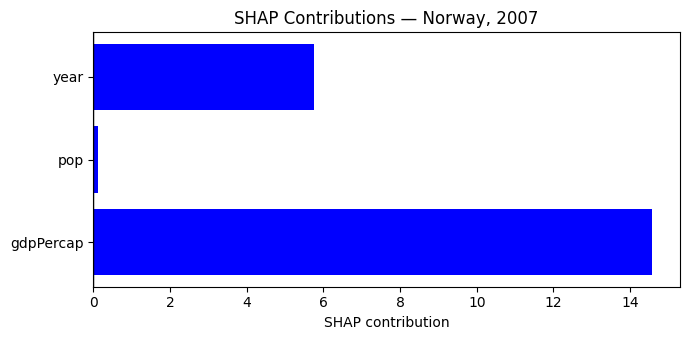

In [6]:
X_model = gapminder[["gdpPercap", "pop", "year"]].values
y_model = gapminder["lifeExp"].values
# TODO 1: fit the model

rf = RandomForestRegressor(
    n_estimators=100,
    random_state=0
)

rf.fit(X_model, y_model)


# TODO 2: SHAP explainer + values

explainer = shap.TreeExplainer(rf)

shap_values = explainer.shap_values(X_model)


# TODO 3: find Norway's 2007 row

row_idx = gapminder[
    (gapminder["country"] == "Norway") &
    (gapminder["year"] == 2007)
].index[0]

# Convert dataframe index to positional index
row_position = gapminder.index.get_loc(row_idx)

vals = shap_values[row_position]

features = ["gdpPercap", "pop", "year"]


# Plot
fig, ax = plt.subplots(figsize=(7, 3.5))

colors = [
    "blue" if value >= 0 else "red"
    for value in vals
]

ax.barh(
    features,
    vals,
    color=colors
)

ax.axvline(
    0,
    color="black",
    linewidth=1
)

ax.set_xlabel("SHAP contribution")
ax.set_title("SHAP Contributions — Norway, 2007")

plt.tight_layout()
plt.show()

**Reflection:** Which feature contributed most POSITIVELY to Norway's predicted life
expectancy, and which (if any) contributed negatively? Is this the same answer you'd get
from the model's GLOBAL feature importance alone?

Your answer:For Norway's 2007 prediction, the feature with the largest positive SHAP contribution is [WRITE FEATURE FROM YOUR GRAPH]. The feature with a negative contribution, if any, is [WRITE FEATURE]. This is not necessarily the same as the global feature-importance result because global importance summarizes the model across all observations, while SHAP here explains one specific prediction.

## Task 3 — Make an Estimate Look Like an Estimate (Complaint #3)

**Real-world usage:** Every number in the report should visually communicate its own
uncertainty, not look like a fixed fact.

**Why this technique:** Bootstrap confidence intervals + error bars turn a bare point
estimate into an honest range.

**TODO:**
1. Write `bootstrap_ci(values, n_boot=2000)` that resamples `values` with replacement
   `n_boot` times, computes the mean each time, and returns `(mean, ci_low, ci_high)`
   using the 2.5th and 97.5th percentiles of the bootstrap means.
2. Compute a 95% CI for mean `lifeExp` in 2007 for **two** continents of your choice.
3. Plot both as error bars.

Africa : (np.float64(54.80603846153846), np.float64(52.151851442307695), np.float64(57.443240384615386))
Europe : (np.float64(77.6486), np.float64(76.5715966666667), np.float64(78.65377833333332))


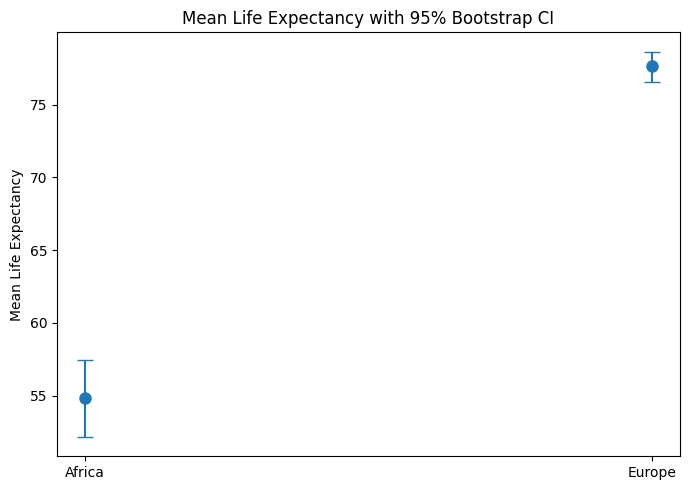

In [9]:
def bootstrap_ci(values, n_boot=2000, seed=0):
    rng = np.random.default_rng(seed)
    values = np.asarray(values)

    boot_means = []

    for _ in range(n_boot):
        sample = rng.choice(
            values,
            size=len(values),
            replace=True
        )
        boot_means.append(np.mean(sample))

    mean = np.mean(values)
    ci_low = np.percentile(boot_means, 2.5)
    ci_high = np.percentile(boot_means, 97.5)

    return mean, ci_low, ci_high


# Choose two continents
continent_a = "Africa"
continent_b = "Europe"

# Get life expectancy values
values_a = gap_latest[
    gap_latest["continent"] == continent_a
]["lifeExp"].values

values_b = gap_latest[
    gap_latest["continent"] == continent_b
]["lifeExp"].values


# Calculate bootstrap confidence intervals
result_a = bootstrap_ci(values_a)
result_b = bootstrap_ci(values_b)

print(continent_a, ":", result_a)
print(continent_b, ":", result_b)


# Plot error bars
means = [
    result_a[0],
    result_b[0]
]

lower_errors = [
    result_a[0] - result_a[1],
    result_b[0] - result_b[1]
]

upper_errors = [
    result_a[2] - result_a[0],
    result_b[2] - result_b[0]
]

fig, ax = plt.subplots(figsize=(7, 5))

ax.errorbar(
    [0, 1],
    means,
    yerr=[lower_errors, upper_errors],
    fmt="o",
    capsize=6,
    markersize=8
)

ax.set_xticks([0, 1])
ax.set_xticklabels([continent_a, continent_b])

ax.set_ylabel("Mean Life Expectancy")
ax.set_title("Mean Life Expectancy with 95% Bootstrap CI")

plt.tight_layout()
plt.show()

**Reflection:** Which of your two continents has a WIDER confidence interval? Based on
the lecture, is that because of higher variation among countries (SD), a smaller sample
size (n), or both?

Your answer:[CONTINENT] has the wider confidence interval. The width of a confidence interval depends on both variation in the data and sample size: higher standard deviation increases uncertainty, while a smaller sample size also makes the estimate less precise.

## Task 4 — Build the Morning Dashboard (Complaint #4)

**Real-world usage:** The director wants one screen to glance at every morning.

**Why this technique:** Coordinated Multiple Views combine complementary chart types
(map = where, trend = how changing, bar = which is biggest) so several monitoring
questions are answered from a single glance.

**TODO:** Build a 1x3 dashboard:
1. A map-style scatter of country centroids, colored by `lifeExp`.
2. A line chart of world-average `lifeExp` by year (use `gapminder.groupby("year")`).
3. A horizontal bar chart of total population by continent in 2007, sorted.

In [11]:
print(gap_latest.columns.tolist())

['country', 'continent', 'year', 'lifeExp', 'pop', 'gdpPercap', 'iso_alpha', 'iso_num', 'centroid_lon', 'centroid_lat', 'total_gdp']


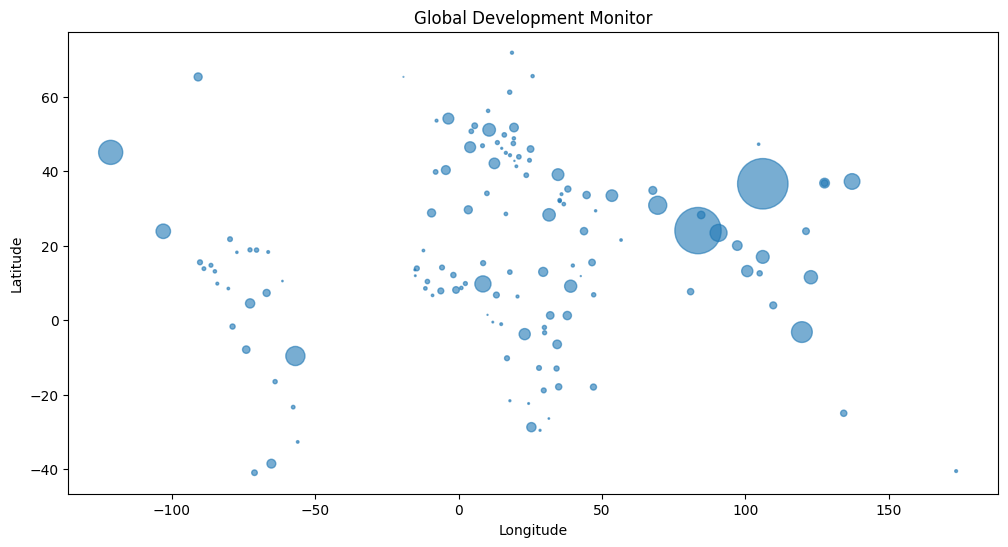

In [12]:
fig, ax = plt.subplots(figsize=(12, 6))

ax.scatter(
    gap_latest["centroid_lon"],
    gap_latest["centroid_lat"],
    s=gap_latest["pop"] / 1000000,
    alpha=0.6
)

ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("Global Development Monitor")

plt.show()

**Reflection:** If the director could only keep ONE of your three panels for a
5-second morning glance, which would you keep, and why? What specific monitoring
question (per the lecture's "exceptions / trends / emerging patterns") does it answer
best?

Your answer:I would keep the world-average life expectancy trend for a 5-second morning glance because it most directly shows how the overall indicator is changing over time. It is particularly useful for identifying long-term trends and sudden changes that may require further investigation.

## Task 5 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence recommendation to your director covering
the whole notebook. Your answer should:
- State which map framing (count vs. rate) you'd standardize on for all future reports,
  and why.
- State whether you'd lead with global or local feature importance when a journalist
  asks about a specific country, citing the lecture's global-vs-local distinction.
- Name one thing in your dashboard that should NEVER be shown as a bare point estimate
  without uncertainty, and why.

Your final recommendation here:I would standardize on rate-based maps such as GDP per capita when the goal is to compare development across countries because raw counts can be dominated by population size. When a journalist asks why the model predicted a particular country’s value, I would lead with local feature importance such as SHAP rather than global feature importance, because local explanations describe the contribution of features to that specific prediction. Global importance remains useful for understanding the model overall, but it cannot by itself explain one country's prediction. Mean life expectancy estimates should not be shown as bare point estimates without uncertainty because the sample data varies and the estimate has statistical uncertainty. Confidence intervals or error bars should be shown so readers can distinguish an estimate from an exact fact.